In [2]:
import pandas as pd
import time
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
df = pd.read_csv(r"C:\Users\HP\Downloads\iris.csv")

df.info()

df.head()

df.isnull().sum()

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

start = time.time()
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)
time1 = time.time() - start
acc1 = accuracy_score(y_test, pred)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

start = time.time()
model_pca = LogisticRegression(max_iter=1000)
model_pca.fit(X_train_pca, y_train)
pred_pca = model_pca.predict(X_test_pca)
time2 = time.time() - start
acc2 = accuracy_score(y_test, pred_pca)


print("Original Features:", X.shape[1])
print("Reduced Features:", X_train_pca.shape[1])

print("\nBefore PCA")
print("Accuracy:", acc1)
print("Execution Time:", time1)

print("\nAfter PCA")
print("Accuracy:", acc2)
print("Execution Time:", time2,"Seconds")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
Original Features: 4
Reduced Features: 2

Before PCA
Accuracy: 1.0
Execution Time: 0.008202075958251953

After PCA
Accuracy: 0.9
Execution Time: 0.004812717437744141 Seconds


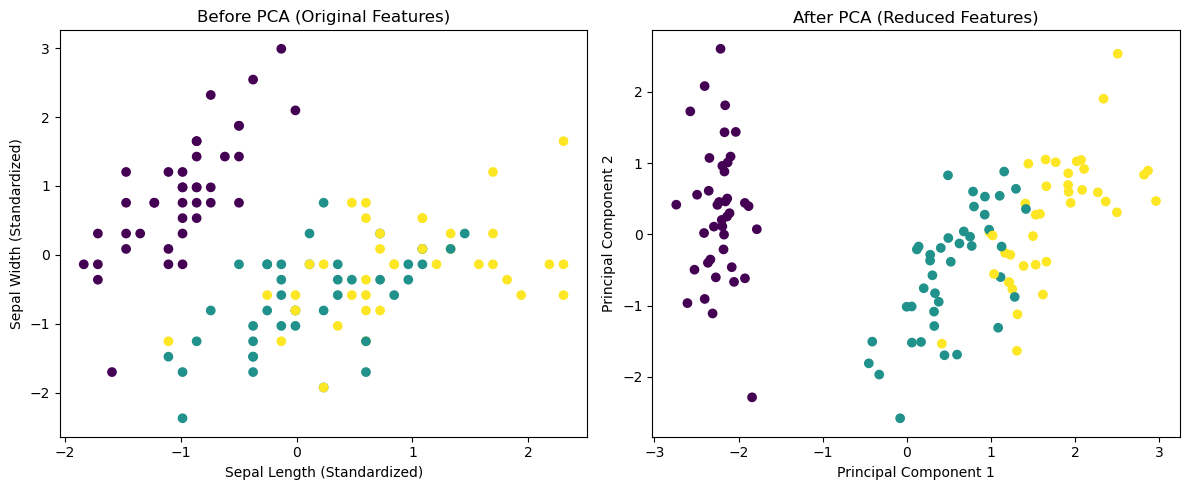

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Before PCA
plt.subplot(1, 2, 1)

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap='viridis'
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("Before PCA (Original Features)")

# After PCA
plt.subplot(1, 2, 2)

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='viridis'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("After PCA (Reduced Features)")

plt.tight_layout()
plt.show()